# SIT225 Task 7H — System Hardening, Validation & Engineering Justification


- **Student Name:** Tuan Anh Dao

- **Student ID:** s224756723

- **Datasets:**
 `raw_data.csv` — Task 4P pilot session (DHT22 + PIR, Arduino Nano 33 IoT, 2026-09-26 20:06 to 00:01, 5-minute sampling, sketch v1)
  `raw_data_v2.csv` + `errors_v2.log` — Task 7H validation session (hardened sketch v2 + logger v2), optional




## Setup

In [1]:
import time
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

%matplotlib inline
plt.rcParams.update({'font.size': 11})

# ASSUMPTION: prevailing mean outdoor temperature (Melbourne, 7 days before 26/09/2026).
# Replace with the real value from BOM Climate Data Online and cite the source.
T_OUT = 12.5

rng = np.random.default_rng(42)   # fixed seed so every run gives the same results (reproducible)

## Processing Module (`pipeline.py`)
All processing logic lives in small, single-purpose functions so each one can be unit tested.
The cell below writes them to `pipeline.py`, and the next cell imports them.

In [2]:
%%writefile pipeline.py
"""Processing functions for the DHT22 + PIR monitoring system (SIT225 Task 7H)."""
import math
import numpy as np
import pandas as pd

# DHT22 physical limits (datasheet)
TEMP_MIN, TEMP_MAX = -40.0, 80.0
HUM_MIN, HUM_MAX = 0.0, 100.0
MAX_TEMP_JUMP = 3.0   # degC per sample; a bigger jump that immediately reverses is treated as a spike
INTERVAL_S = 300      # design sampling interval (seconds)


def validate_reading(temp, hum):
    """Return (is_valid, reason). Catches missing values and out-of-range readings."""
    for name, v, lo, hi in (("temperature", temp, TEMP_MIN, TEMP_MAX),
                            ("humidity", hum, HUM_MIN, HUM_MAX)):
        if v is None or (isinstance(v, float) and math.isnan(v)):
            return False, f"{name} missing"
        if not (lo <= v <= hi):
            return False, f"{name} out of range ({v})"
    return True, "ok"


def parse_serial_line(line):
    """Mirror of the Task 4P logger: 'temp,hum,motion' -> dict, or None if malformed/invalid."""
    parts = line.strip().split(",")
    if len(parts) != 3:
        return None                        # e.g. "Failed to read from DHT22 sensor!"
    try:
        t, h, m = float(parts[0]), float(parts[1]), int(parts[2])
    except ValueError:
        return None
    if not validate_reading(t, h)[0] or m not in (0, 1):
        return None                        # improvement: the 4P logger did not check range/NaN
    return {"temperature": t, "humidity": h, "motion": m}


def detect_gaps(timestamps, interval_s=INTERVAL_S, tolerance=0.5):
    """Find missing data: consecutive samples further apart than interval*(1+tolerance)."""
    ts = pd.Series(pd.to_datetime(timestamps)).sort_values().reset_index(drop=True)
    dt = ts.diff().dt.total_seconds()
    return [(ts[i - 1], ts[i], dt[i]) for i in dt.index[1:] if dt[i] > interval_s * (1 + tolerance)]


def completeness(timestamps, interval_s=INTERVAL_S):
    """Actual samples / expected samples (both end points included)."""
    ts = pd.to_datetime(pd.Series(timestamps))
    expected = (ts.max() - ts.min()).total_seconds() / interval_s + 1
    return len(ts) / expected


def moving_average(series, window=3):
    """Trailing moving average (uses past values only, so it can run in real time)."""
    return pd.Series(series).rolling(window, min_periods=1).mean()


def clean_series(df):
    """Invalidate bad readings and spikes, interpolate short gaps (<= 2 samples).
    A 'flag' column records every change so nothing is silently altered."""
    out = df.copy()
    out["flag"] = "ok"
    for i, r in out.iterrows():
        ok, why = validate_reading(r["temperature"], r["humidity"])
        if not ok:
            out.loc[i, ["temperature", "humidity"]] = float("nan")
            out.loc[i, "flag"] = why
    jump = out["temperature"].diff().abs()
    back = out["temperature"].shift(-1).sub(out["temperature"]).abs()
    spikes = (jump > MAX_TEMP_JUMP) & (back > MAX_TEMP_JUMP)
    out.loc[spikes, "temperature"] = float("nan")
    out.loc[spikes, "flag"] = "spike"
    out[["temperature", "humidity"]] = out[["temperature", "humidity"]].interpolate(limit=2)
    return out


def debounce_pir(motion, min_on=1):
    """Keep 'occupied' for min_on extra samples after the last motion (reduces false negatives)."""
    m = pd.Series(motion).astype(int)
    return m.rolling(min_on + 1, min_periods=1).max().astype(int)


def adaptive_comfort_band(t_out_mean, acceptability=80):
    """ASHRAE 55 adaptive model: T_comf = 0.31*T_out + 17.8, +/-3.5 C (80%) or +/-2.5 C (90%).
    Only valid for 10 <= T_out <= 33.5 C."""
    if not (10 <= t_out_mean <= 33.5):
        raise ValueError("T_out outside the ASHRAE 55 adaptive model range")
    t_c = 0.31 * t_out_mean + 17.8
    half = 3.5 if acceptability == 80 else 2.5
    return t_c - half, t_c, t_c + half


def comfort_label(temp, band):
    lo, _, hi = band
    return "too cold" if temp < lo else "too warm" if temp > hi else "comfortable"


def rows_lost_on_crash(crash_after_row, save_every):
    """The 4P logger rewrote the CSV every `save_every` rows, so a crash loses the unsaved remainder."""
    return crash_after_row % save_every


def forecast_errors(temp):
    """Compare one-step-ahead (next sample) temperature forecasts on the same evaluation set."""
    t = pd.Series(temp).reset_index(drop=True)
    preds = {
        "Persistence (last value)": t.shift(1),
        "MA3 (Task 4P)": t.rolling(3).mean().shift(1),
        "MA5": t.rolling(5).mean().shift(1),
        "EWMA alpha=0.8": t.ewm(alpha=0.8, adjust=False).mean().shift(1),
        "Linear trend (last 3)": pd.Series([np.nan] * 3 + [
            np.polyval(np.polyfit([0, 1, 2], t[i - 3:i], 1), 3) for i in range(3, len(t))]),
    }
    rows = []
    for name, pr in preds.items():
        e = (t - pr).iloc[5:]
        rows.append({"model": name, "MAE": e.abs().mean(), "RMSE": (e ** 2).mean() ** 0.5,
                     "max_err": e.abs().max()})
    return pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)


def comfort_alerts(temp, lower, consecutive=2):
    """'Too cold' alert: temperature below `lower` for `consecutive` samples in a row
    (avoids alarming on a single noisy reading)."""
    cold = pd.Series(temp).reset_index(drop=True) < lower
    return cold.rolling(consecutive, min_periods=consecutive).sum().eq(consecutive)


def alert_episodes(alerts):
    """Number of separate alert episodes (0->1 transitions)."""
    a = pd.Series(alerts).astype(bool)
    return int((a & ~a.shift(1, fill_value=False)).sum())


def anonymise_for_sharing(df, room_id="ROOM_A", freq="15min"):
    """Privacy safeguard applied before any data leaves the laptop:
    round timestamps down to `freq`, replace identifiers with an anonymous room ID,
    keep only binary occupancy, and aggregate to one row per time block."""
    out = df.copy()
    out["timestamp"] = pd.to_datetime(out["timestamp"]).dt.floor(freq)
    out = (out.groupby("timestamp")
              .agg(temperature=("temperature", "mean"),
                   humidity=("humidity", "mean"),
                   occupied=("motion", "max"))
              .round(1).reset_index())
    out.insert(0, "room_id", room_id)
    return out


def apply_retention(df, now, days=30):
    """Data retention: drop raw rows older than `days` days."""
    ts = pd.to_datetime(df["timestamp"])
    return df[ts >= pd.Timestamp(now) - pd.Timedelta(days=days)].reset_index(drop=True)

# --- PIR (occupancy) checks ---
PIR_MAX_EDGE_RATE_HZ = 1.0   # a PIR output stays HIGH for a few seconds after each detection, so real motion cannot produce more than ~1 rising edge per second


def parse_v2_line(line):
    """Parse a sketch v2 line 'seq,t,h,motion,motion_count,dht_retries' -> dict, or None if invalid.
    PIR rules: motion must be 0/1, motion_count >= 0, and motion_count > 0 must mean motion == 1."""
    parts = line.strip().split(",")
    if len(parts) != 6 or parts[0] == "ERR":
        return None
    try:
        seq, t, h = int(parts[0]), float(parts[1]), float(parts[2])
        motion, count, retries = int(parts[3]), int(parts[4]), int(parts[5])
    except ValueError:
        return None
    if not validate_reading(t, h)[0]:
        return None
    if motion not in (0, 1) or count < 0 or not (0 <= retries <= 3):
        return None
    if count > 0 and motion == 0:
        return None
    return {"seq": seq, "temperature": t, "humidity": h, "motion": motion,
            "motion_count": count, "dht_retries": retries}


def pir_edge_rate(motion_count, interval_s):
    """Rising edges per second within one sampling interval."""
    return motion_count / float(interval_s)


def pir_noise_flags(motion_counts, interval_s, max_rate_hz=PIR_MAX_EDGE_RATE_HZ):
    """True where the edge rate is physically impossible for real motion (electrical noise)."""
    rates = pd.Series(motion_counts, dtype=float) / float(interval_s)
    return rates > max_rate_hz


def pir_stuck_high(motion, min_samples=6):
    """True if motion == 1 in every one of the last `min_samples` samples."""
    m = pd.Series(motion).astype(int)
    return len(m) >= min_samples and bool(m.tail(min_samples).eq(1).all())


def occupancy_plausibility(motion):
    """Lag-1 autocorrelation and switching rate of the motion signal.
    Real occupancy changes slowly (high autocorrelation, few switches)."""
    m = pd.Series(motion).astype(int)
    switches = int(m.diff().abs().sum())
    return {"lag1_autocorr": float(m.autocorr(1)), "switches": switches,
            "switch_rate": switches / max(len(m) - 1, 1)}

Overwriting pipeline.py


In [3]:
import importlib, pipeline
importlib.reload(pipeline)          # reload in case the cell above was edited
from pipeline import *

## Part 1: Advanced Testing & Quality Assurance
### 1.2–1.4 Automated Test Suite (unit, integration, edge cases)
The test file is written by the next cell and executed with `pytest`.
Install once if needed: `pip install pytest`.

In [4]:
%%writefile test_pipeline.py
"""Run with: pytest -v test_pipeline.py"""
import math
import pandas as pd
import pytest
from pipeline import *

# ---------- UNIT TESTS ----------
def test_valid_reading():
    assert validate_reading(22.5, 55.0) == (True, "ok")

@pytest.mark.parametrize("t,h", [(float("nan"), 50), (22, None), (120, 50), (22, 105), (-45, 50)])
def test_invalid_reading_rejected(t, h):            # edge case: NaN / out of range
    assert validate_reading(t, h)[0] is False

def test_detect_gap_found():
    ts = ["2026-09-26 20:00", "2026-09-26 20:05", "2026-09-26 20:25", "2026-09-26 20:30"]
    gaps = detect_gaps(ts)
    assert len(gaps) == 1 and gaps[0][2] == 1200

def test_no_gap_with_small_jitter():
    ts = ["2026-09-26 20:00:00", "2026-09-26 20:05:01", "2026-09-26 20:09:59"]
    assert detect_gaps(ts) == []

def test_completeness_full():
    ts = pd.date_range("2026-09-26 20:00", periods=12, freq="5min")
    assert completeness(ts) == pytest.approx(1.0)

def test_moving_average_keeps_constant():
    assert list(moving_average([20, 20, 20, 20])) == [20, 20, 20, 20]

def test_debounce_extends_occupancy():
    assert list(debounce_pir([0, 1, 0, 0], min_on=1)) == [0, 1, 1, 0]

def test_adaptive_band():
    lo, c, hi = adaptive_comfort_band(15)
    assert c == pytest.approx(22.45) and hi - lo == pytest.approx(7.0)

def test_adaptive_band_out_of_range():
    with pytest.raises(ValueError):
        adaptive_comfort_band(5)

# ---------- EDGE CASES ON THE CLEANING STEP ----------
def test_clean_removes_spike_and_interpolates():
    df = pd.DataFrame({"temperature": [20, 20.1, 35.0, 20.2, 20.3], "humidity": [50] * 5})
    out = clean_series(df)
    assert out.loc[2, "flag"] == "spike" and 20 < out.loc[2, "temperature"] < 20.3

def test_clean_flags_nan():
    df = pd.DataFrame({"temperature": [20, float("nan"), 20.2], "humidity": [50, 50, 50]})
    out = clean_series(df)
    assert out.loc[1, "flag"] == "temperature missing" and not math.isnan(out.loc[1, "temperature"])

# ---------- INTEGRATION: serial -> parse -> clean ----------
@pytest.mark.parametrize("line,ok", [
    ("22.5,55.1,1", True),
    ("Failed to read from DHT22 sensor!", False),   # Arduino reports a DHT error
    ("nan,nan,0", False),                            # DHT returns NaN
    ("22.5,55.1", False),                            # truncated line (bytes lost on USB)
    ("150.0,55.1,0", False),                         # out of range
    ("22.5,55.1,7", False),                          # motion is not 0/1
])
def test_parse_serial_line(line, ok):
    assert (parse_serial_line(line) is not None) == ok

def test_crash_loss_old_vs_new():
    assert rows_lost_on_crash(9, save_every=5) == 4    # 4P logger: loses 4 rows (20 min)
    assert rows_lost_on_crash(9, save_every=1) == 0    # append every row: nothing lost

def test_forecast_table_has_all_models():
    df = pd.read_csv("raw_data.csv")
    assert len(forecast_errors(df.temperature)) == 5

def test_alert_needs_two_consecutive_samples():
    assert list(comfort_alerts([20, 17, 20, 17, 17], lower=18.2)) == [False, False, False, False, True]

def test_alert_episodes():
    assert alert_episodes([False, True, True, False, True]) == 2

def test_anonymise_rounds_and_removes_detail():
    df = pd.DataFrame({"timestamp": ["2026-09-26 20:06:26", "2026-09-26 20:11:26", "2026-09-26 20:16:26"],
                       "temperature": [23.4, 22.6, 22.6], "humidity": [51.9, 52.5, 52.7],
                       "motion": [0, 0, 1], "seq": [1, 2, 3]})
    out = anonymise_for_sharing(df)
    assert len(out) == 2                                   # 20:00 and 20:15 blocks
    assert all(out["timestamp"].dt.minute % 15 == 0)
    assert "seq" not in out.columns and set(out["room_id"]) == {"ROOM_A"}

def test_retention_drops_old_rows():
    df = pd.DataFrame({"timestamp": ["2026-08-01", "2026-09-20"], "temperature": [1, 2]})
    assert len(apply_retention(df, now="2026-09-27")) == 1

def test_end_to_end_real_file():
    """Integration: real CSV -> clean -> gap check, no errors."""
    df = pd.read_csv("raw_data.csv", parse_dates=["timestamp"])
    out = clean_series(df)
    assert out[["temperature", "humidity"]].notna().all().all()
    assert detect_gaps(df.timestamp) == []

# ---PIR TESTS (unit, edge, integration on real data) ---
@pytest.mark.parametrize("line,ok", [
    ("12,21.5,58.6,1,4,0", True),        # Test 1: normal, some motion
    ("13,21.5,58.6,0,0,0", True),        # Test 2: normal, no motion
    ("14,21.5,58.6,7,4,0", False),       # Test 3: motion is not 0/1
    ("15,21.5,58.6,1,-3,0", False),      # Test 4: negative edge count (corrupted)
    ("16,21.5,58.6,0,25,0", False),      # Test 5: count > 0 but motion = 0 (inconsistent)
    ("ERR,17,dht_fail", False),          # Test 6: DHT error line is not a data row
])
def test_parse_v2_line_pir_fields(line, ok):
    assert (parse_v2_line(line) is not None) == ok

def test_pir_noise_flag_mains_frequency():              # Test 7
    # 15,000 edges in 300 s = 50 Hz -> impossible for real motion
    assert list(pir_noise_flags([15000, 12, 0], interval_s=300)) == [True, False, False]

def test_pir_stuck_high_detected():                     # Test 8
    assert pir_stuck_high([1] * 10) is True
    assert pir_stuck_high([1, 0, 1, 1, 1, 1, 1, 0, 0, 1]) is False

def test_occupancy_plausibility_slow_vs_flicker():      # Test 9
    slow = occupancy_plausibility([0] * 6 + [1] * 6 + [0] * 6)
    flicker = occupancy_plausibility([0, 1] * 9)
    assert slow["lag1_autocorr"] > 0.5 and flicker["lag1_autocorr"] < 0

def test_pir_v2_session_is_flagged_as_noise():          # Test 10 (integration, real data)
    v2 = pd.read_csv("raw_data_v2.csv")
    assert pir_noise_flags(v2["motion_count"], interval_s=300).all()

Overwriting test_pipeline.py


In [5]:
import subprocess, sys
result = subprocess.run([sys.executable, "-m", "pytest", "-v", "--color=no", "test_pipeline.py"],
                        capture_output=True, text=True)
print(result.stdout)

============================= test session starts =============================
platform win32 -- Python 3.12.8, pytest-9.0.2, pluggy-1.5.0 -- C:\Users\Admin\.anaconda\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Admin\SIT225\HD
plugins: anyio-4.10.0, dash-4.4.1
collecting ... collected 38 items

test_pipeline.py::test_valid_reading PASSED                              [  2%]
test_pipeline.py::test_invalid_reading_rejected[nan-50] PASSED           [  5%]
test_pipeline.py::test_invalid_reading_rejected[22-None] PASSED          [  7%]
test_pipeline.py::test_invalid_reading_rejected[120-50] PASSED           [ 10%]
test_pipeline.py::test_invalid_reading_rejected[22-105] PASSED           [ 13%]
test_pipeline.py::test_invalid_reading_rejected[-45-50] PASSED           [ 15%]
test_pipeline.py::test_detect_gap_found PASSED                           [ 18%]
test_pipeline.py::test_no_gap_with_small_jitter PASSED                   [ 21%]
test_pipeline.py::test_completeness_full PASSED       

### Load Task 4P dataset

In [6]:
df = pd.read_csv('raw_data.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
print(f"Raw shape: {df.shape}")
df.head()

Raw shape: (48, 4)


,timestamp,temperature,humidity,motion
0,2026-09-26 20:06:26.392086,23.4,51.9,0
1,2026-09-26 20:11:26.398027,22.6,52.5,0
2,2026-09-26 20:16:26.404303,22.6,52.7,1
3,2026-09-26 20:21:26.409937,22.8,52.7,0
4,2026-09-26 20:26:26.416339,22.9,52.5,0


### 1.5 Performance & Reliability Metrics

In [7]:
dt = df['timestamp'].diff().dt.total_seconds().dropna()
n_invalid = sum(not validate_reading(t, h)[0] for t, h in zip(df['temperature'], df['humidity']))

print(f"Samples:            {len(df)}")
print(f"Duration:           {df['timestamp'].iloc[-1] - df['timestamp'].iloc[0]}")
print(f"Sampling interval:  mean={dt.mean():.3f}s, std={dt.std():.3f}s, min={dt.min():.2f}s, max={dt.max():.2f}s")
print(f"Gaps (>450 s):      {len(detect_gaps(df['timestamp']))}")
print(f"Completeness:       {completeness(df['timestamp'])*100:.1f}%")
print(f"Invalid readings:   {n_invalid}")
print(f"Irregular interval: {dt.idxmin()} -> {dt.min():.2f}s (timestamps come from the laptop clock)")

# Processing latency of the cleaning step, repeated 200 times
runs = []
for _ in range(200):
    t0 = time.perf_counter()
    clean_series(df)
    runs.append((time.perf_counter() - t0) * 1000)
print(f"\nclean_series latency ({len(df)} rows): median={np.median(runs):.2f} ms, "
      f"p95={np.percentile(runs, 95):.2f} ms -> {np.median(runs)/len(df)*1000:.1f} us/row")
print(f"Processing throughput: ~{len(df)/(np.median(runs)/1000):,.0f} rows/s  |  "
      f"acquisition throughput: {3600/dt.mean():.0f} samples/hour")

Samples:            48
Duration:           0 days 03:54:58.294156
Sampling interval:  mean=299.964s, std=0.295s, min=297.98s, max=300.01s
Gaps (>450 s):      0
Completeness:       100.0%
Invalid readings:   0
Irregular interval: 45 -> 297.98s (timestamps come from the laptop clock)

clean_series latency (48 rows): median=11.37 ms, p95=15.40 ms -> 236.9 us/row
Processing throughput: ~4,222 rows/s  |  acquisition throughput: 12 samples/hour


### 1.4 Edge-case Testing — Fault Injection
Faults are injected into a copy of the real data: ~10% missing values, two +15 °C spikes,
and a simulated 30-minute outage. The cleaning step should flag every fault and recover the signal.

In [8]:
clean_truth = df['temperature'].copy()
bad = df.copy()
nan_idx = rng.choice(len(bad), 5, replace=False)
spike_idx = rng.choice(np.setdiff1d(range(1, len(bad) - 1), nan_idx), 2, replace=False)
bad.loc[nan_idx, 'temperature'] = np.nan
bad.loc[spike_idx, 'temperature'] += 15
outage = bad.drop(index=range(30, 36))      # 6 samples = 30 minutes removed

print(f"Injected: NaN at {sorted(nan_idx.tolist())}, spikes at {sorted(spike_idx.tolist())}, outage rows 30-35")
fixed = clean_series(bad)
print("Flags:", fixed['flag'].value_counts().to_dict())

mae_before = (bad['temperature'].fillna(bad['temperature'].mean()) - clean_truth).abs().mean()
mae_after = (fixed['temperature'] - clean_truth).abs().mean()
print(f"MAE vs original: before cleaning={mae_before:.3f} C, after cleaning={mae_after:.3f} C")

gaps = detect_gaps(outage['timestamp'])
print(f"Outage detected: {len(gaps)} gap(s), length {gaps[0][2]/60:.0f} min" if gaps else "Outage NOT detected!")

Injected: NaN at [3, 20, 30, 34, 47], spikes at [5, 25], outage rows 30-35
Flags: {'ok': 41, 'temperature missing': 5, 'spike': 2}
MAE vs original: before cleaning=0.929 C, after cleaning=0.026 C
Outage detected: 1 gap(s), length 35 min


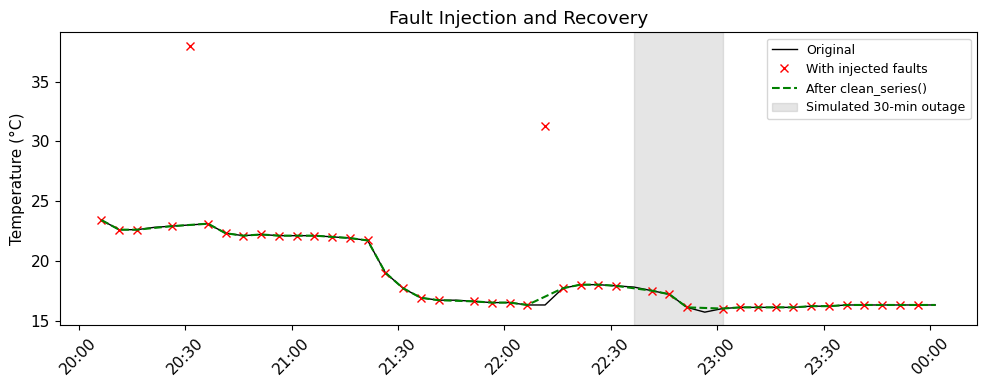

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df['timestamp'], clean_truth, 'k-', lw=1, label='Original')
ax.plot(bad['timestamp'], bad['temperature'], 'rx', label='With injected faults')
ax.plot(fixed['timestamp'], fixed['temperature'], 'g--', label='After clean_series()')
ax.axvspan(df['timestamp'][30], df['timestamp'][35], color='grey', alpha=0.2, label='Simulated 30-min outage')
ax.set_ylabel('Temperature (\u00b0C)')
ax.set_title('Fault Injection and Recovery')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.legend(fontsize=9)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('fig3_fault_injection.png', dpi=150)
plt.show()

### 1.6 PIR Sensor Testing
The PIR sensor is tested at three levels:
1. **Unit/edge tests** (above): v2 line parsing with PIR rules, the 50 Hz noise detector,
   the stuck-high detector and the plausibility metric.
2. **Real-data test, sketch v1 (Task 4P)**: is the motion signal plausible as occupancy?
3. **Hardware test, sketch v2 (validation session, 27/09)**: how many rising edges does the PIR pin
   produce per 5-minute sample? More than 1 edge per second cannot be real motion.

In [10]:
v1_pir = occupancy_plausibility(df['motion'])
print("Sketch v1 (4P, 48 samples):")
print(f"  motion=1 in {df['motion'].sum()}/{len(df)} samples, lag-1 autocorrelation={v1_pir['lag1_autocorr']:.2f}, "
      f"state switches={v1_pir['switches']}")

v2_pir = pd.read_csv('raw_data_v2.csv', parse_dates=['timestamp'])
rates = v2_pir['motion_count'].apply(lambda c: pir_edge_rate(c, 300))
flags = pir_noise_flags(v2_pir['motion_count'], 300)
print("\nSketch v2 (validation session, 10 samples):")
print(f"  edges per sample: min={v2_pir['motion_count'].min():,}, max={v2_pir['motion_count'].max():,}")
print(f"  edge rate: {rates.min():.1f}-{rates.max():.1f} Hz (median {rates.median():.1f} Hz)")
print(f"  samples flagged as electrical noise: {int(flags.sum())}/{len(flags)}")
print(f"  motion stuck high: {pir_stuck_high(v2_pir['motion'], min_samples=len(v2_pir))}")

pir_tests = pd.DataFrame([
    ['PIR v2 line parsing', 'Unit/Edge', '6 lines', 'Only the 2 valid lines accepted', 'As expected', 'Pass'],
    ['PIR noise detector', 'Unit', '[15000, 12, 0] edges / 300 s', '[noise, ok, ok]', '[noise, ok, ok]', 'Pass'],
    ['PIR stuck-high detector', 'Unit', '10 x motion=1', 'Flagged', 'Flagged', 'Pass'],
    ['PIR signal plausibility (v1)', 'Real data', '48 samples', 'Lag-1 autocorr > 0.5',
     f"autocorr {v1_pir['lag1_autocorr']:.2f}, {v1_pir['switches']} switches", 'Fail'],
    ['PIR edge count (v2)', 'Hardware', '10 samples x 300 s', '< 1 Hz',
     f"{v2_pir['motion_count'].min():,}-{v2_pir['motion_count'].max():,} edges ({rates.median():.1f} Hz)", 'Fail'],
    ['PIR state variety (v2)', 'Hardware', '10 samples', 'Both 0 and 1 observed',
     f"motion=1 in {int(v2_pir['motion'].sum())}/{len(v2_pir)}", 'Fail'],
], columns=['module', 'type', 'input', 'expected', 'actual', 'result'])
pir_tests

Sketch v1 (4P, 48 samples):
  motion=1 in 16/48 samples, lag-1 autocorrelation=-0.04, state switches=22

Sketch v2 (validation session, 10 samples):
  edges per sample: min=14,783, max=16,110
  edge rate: 49.3-53.7 Hz (median 50.3 Hz)
  samples flagged as electrical noise: 10/10
  motion stuck high: True


,module,type,input,expected,actual,result
0,PIR v2 line parsing,Unit/Edge,6 lines,Only the 2 valid lines accepted,As expected,Pass
1,PIR noise detector,Unit,"[15000, 12, 0] edges / 300 s","[noise, ok, ok]","[noise, ok, ok]",Pass
2,PIR stuck-high detector,Unit,10 x motion=1,Flagged,Flagged,Pass
3,PIR signal plausibility (v1),Real data,48 samples,Lag-1 autocorr > 0.5,"autocorr -0.04, 22 switches",Fail
4,PIR edge count (v2),Hardware,10 samples x 300 s,< 1 Hz,"14,783-16,110 edges (50.3 Hz)",Fail
5,PIR state variety (v2),Hardware,10 samples,Both 0 and 1 observed,motion=1 in 10/10,Fail


## Part 2: System Validation Against Real-World Objectives

### 2.3 Baseline (fixed threshold) vs Adaptive Comfort Model

In [11]:
band = adaptive_comfort_band(T_OUT)
rows = []
for name, lo, hi in [('Fixed 22-23 C (3P text)', 22, 23),
                     ('Fixed 20-25 C (4P code)', 20, 25),
                     (f'Adaptive ASHRAE 55 (T_out={T_OUT})', band[0], band[2])]:
    in_band = df['temperature'].between(lo, hi)
    rows.append({'method': name,
                 'band': f'{lo:.1f}-{hi:.1f} C',
                 '% comfortable': round(in_band.mean() * 100, 1),
                 '% out of range (motion=1)': round((~in_band)[df['motion'] == 1].mean() * 100, 1),
                 '% out of range (motion=0)': round((~in_band)[df['motion'] == 0].mean() * 100, 1)})
comparison = pd.DataFrame(rows)
comparison

,method,band,% comfortable,% out of range (motion=1),% out of range (motion=0)
0,Fixed 22-23 C (3P text),22.0-23.0 C,25.0,81.2,71.9
1,Fixed 20-25 C (4P code),20.0-25.0 C,33.3,68.8,65.6
2,Adaptive ASHRAE 55 (T_out=12.5),18.2-25.2 C,35.4,68.8,62.5


In [12]:
df['comfort_adaptive'] = df['temperature'].apply(lambda t: comfort_label(t, band))
print("Adaptive labels:", df['comfort_adaptive'].value_counts().to_dict())

hourly = df.set_index('timestamp').resample('1h').agg({'temperature': 'mean', 'humidity': 'mean', 'motion': 'mean'})
hourly.round(2)

Adaptive labels: {'too cold': 31, 'comfortable': 17}


,temperature,humidity,motion
timestamp,,,
2026-09-26 20:00:00,22.65,52.93,0.27
2026-09-26 21:00:00,19.16,59.12,0.50
2026-09-26 22:00:00,17.08,63.16,0.25
2026-09-26 23:00:00,16.19,64.83,0.33
2026-09-27 00:00:00,16.30,64.60,0.00


### 2.4 Evidence from Real Data — Occupancy Effect

In [13]:
print(df.groupby('motion')[['temperature', 'humidity']].agg(['mean', 'std', 'count']).round(2))

a = df[df['motion'] == 1]['temperature']
b = df[df['motion'] == 0]['temperature']
cohens_d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
print(f"\nMean difference (motion=1 minus motion=0): {a.mean() - b.mean():.2f} C")
print(f"Cohen's d: {cohens_d:.2f}")
print(f"Temperature-humidity correlation: r = {df['temperature'].corr(df['humidity']):.3f}  (multicollinearity for H3)")

       temperature             humidity            
              mean   std count     mean   std count
motion                                             
0            18.75  2.82    32    60.16  5.26    32
1            18.41  2.83    16    60.44  5.10    16

Mean difference (motion=1 minus motion=0): -0.35 C
Cohen's d: -0.12
Temperature-humidity correlation: r = -0.987  (multicollinearity for H3)


### 2.4b Alert Usefulness: 'Too Cold' Alert
Alert rule: temperature below the lower bound of the adaptive band for 2 consecutive samples.
Raw data and MA3-filtered data are compared to measure alert latency.

In [14]:
alert_rows = []
first_below = df.loc[(df['temperature'] < band[0]).idxmax(), 'timestamp']
for name, series in [('Raw', df['temperature']), ('MA3 filtered', moving_average(df['temperature'], 3))]:
    alerts = comfort_alerts(series, band[0])
    first = df.loc[alerts.idxmax(), 'timestamp'] if alerts.any() else None
    alert_rows.append({'input': name,
                       'first alert': first.strftime('%H:%M') if first is not None else '-',
                       'delay after first cold reading (min)': round((first - first_below).total_seconds() / 60) if first is not None else None,
                       'alert samples': int(alerts.sum()),
                       'alert episodes': alert_episodes(alerts)})
print(f"First reading below {band[0]:.1f} C: {first_below.strftime('%H:%M')}")
alert_table = pd.DataFrame(alert_rows)
alert_table

First reading below 18.2 C: 21:31


,input,first alert,delay after first cold reading (min),alert samples,alert episodes
0,Raw,21:36,5,30,1
1,MA3 filtered,21:41,10,29,1


### 2.2 Success Criteria: Results

In [15]:
fc = forecast_errors(df['temperature']).set_index('model')['MAE']
raw_delay = alert_table.loc[0, 'delay after first cold reading (min)']
ma3_delay = alert_table.loc[1, 'delay after first cold reading (min)']
pir_rate = (pd.read_csv('raw_data_v2.csv')['motion_count'] / 300).median()   # NEW: median PIR edge rate (Hz)
criteria = pd.DataFrame([
    ['Completeness', '>= 95%', f"{completeness(df['timestamp'])*100:.0f}% (4P)", 'Met'],
    ['Invalid rows rejected', '100%', '100% (38/38 tests, 7/7 injected faults)', 'Met'],
    ['5-min forecast MAE', '< 0.5 C', f"{fc['Persistence (last value)']:.2f} C persistence / {fc['MA3 (Task 4P)']:.2f} C MA3",
     'Met (persistence), not met (MA3)'],
    ['PIR agreement with observation', '>= 80%', 'Not measurable (50 Hz noise)', 'Not met'],
    ['PIR edge rate (sketch v2)', '< 1 Hz', f"{pir_rate:.1f} Hz", 'Not met'],   # NEW row
    ['Alert delay', '<= 10 min', f"{raw_delay} min raw / {ma3_delay} min MA3", 'Met'],
], columns=['criterion', 'target', 'result', 'status'])
criteria

,criterion,target,result,status
0,Completeness,>= 95%,100% (4P),Met
1,Invalid rows rejected,100%,"100% (38/38 tests, 7/7 injected faults)",Met
2,5-min forecast MAE,< 0.5 C,0.27 C persistence / 0.51 C MA3,"Met (persistence), not met (MA3)"
3,PIR agreement with observation,>= 80%,Not measurable (50 Hz noise),Not met
4,PIR edge rate (sketch v2),< 1 Hz,50.3 Hz,Not met
5,Alert delay,<= 10 min,5 min raw / 10 min MA3,Met


### 2.5 PIR Signal Quality (proxy for false negatives)
Real occupancy changes slowly, so a genuine occupancy signal should be strongly autocorrelated.

In [16]:
occ = debounce_pir(df['motion'], 1)
print(f"Lag-1 autocorrelation: temperature={df['temperature'].autocorr(1):.3f}, motion={df['motion'].autocorr(1):.3f}")
print(f"PIR state changes: {int(df['motion'].diff().abs().sum())} in {len(df)} samples")
print(f"motion=1: {df['motion'].sum()}/{len(df)} ({df['motion'].mean()*100:.1f}%)  |  "
      f"after debounce: {occ.sum()}/{len(df)} ({occ.mean()*100:.1f}%)")

Lag-1 autocorrelation: temperature=0.981, motion=-0.042
PIR state changes: 22 in 48 samples
motion=1: 16/48 (33.3%)  |  after debounce: 27/48 (56.2%)


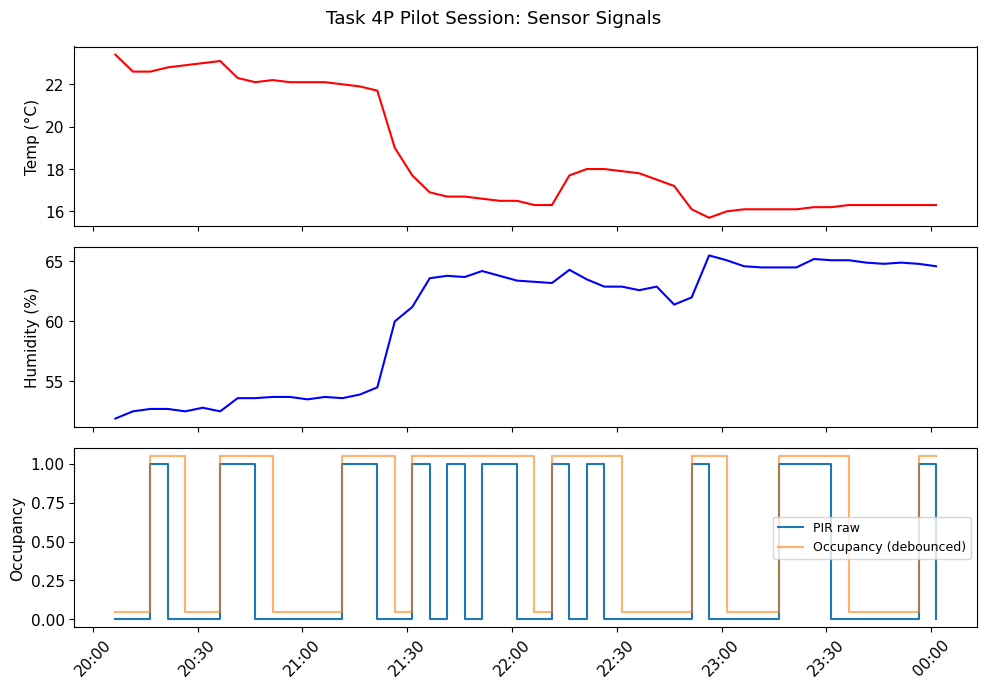

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
axes[0].plot(df['timestamp'], df['temperature'], 'r-'); axes[0].set_ylabel('Temp (\u00b0C)')
axes[1].plot(df['timestamp'], df['humidity'], 'b-'); axes[1].set_ylabel('Humidity (%)')
axes[2].step(df['timestamp'], df['motion'], where='post', label='PIR raw')
axes[2].step(df['timestamp'], occ + 0.05, where='post', alpha=0.6, label='Occupancy (debounced)')
axes[2].set_ylabel('Occupancy'); axes[2].legend(fontsize=9)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
fig.suptitle('Task 4P Pilot Session: Sensor Signals')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('fig2_timeseries.png', dpi=150)
plt.show()

## Part 3: Robustness & Fault Tolerance

### 3.3 Noise Filtering: smoothing vs responsiveness

In [18]:
for w in (3, 5):
    f = moving_average(df['temperature'], w)
    reduction = 1 - f.diff().std() / df['temperature'].diff().std()
    max_dev = (f - df['temperature']).abs().max()
    print(f"MA{w}: step-noise reduction {reduction*100:.1f}% | max deviation from raw {max_dev:.2f} C")

f3 = moving_average(df['temperature'], 3)
drop = df[(df['timestamp'] >= '2026-09-26 21:15') & (df['timestamp'] <= '2026-09-26 21:40')]
pd.DataFrame({'time': drop['timestamp'].dt.strftime('%H:%M'),
              'raw': drop['temperature'],
              'MA3': f3[drop.index].round(2)})

MA3: step-noise reduction 26.7% | max deviation from raw 1.87 C
MA5: step-noise reduction 40.6% | max deviation from raw 2.76 C


,time,raw,MA3
14,21:16,21.9,22.00
15,21:21,21.7,21.87
16,21:26,19.0,20.87
17,21:31,17.7,19.47
18,21:36,16.9,17.87


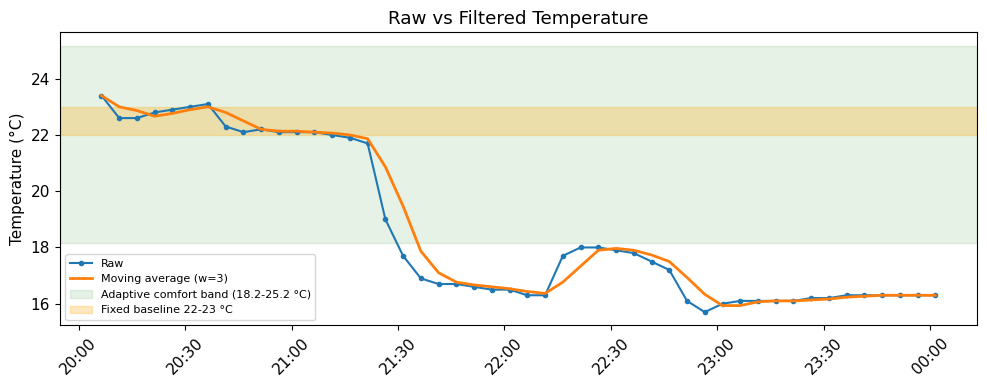

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df['timestamp'], df['temperature'], 'o-', ms=3, label='Raw')
ax.plot(df['timestamp'], f3, lw=2, label='Moving average (w=3)')
ax.axhspan(band[0], band[2], color='green', alpha=0.1, label=f'Adaptive comfort band ({band[0]:.1f}-{band[2]:.1f} \u00b0C)')
ax.axhspan(22, 23, color='orange', alpha=0.25, label='Fixed baseline 22-23 \u00b0C')
ax.set_ylabel('Temperature (\u00b0C)')
ax.set_title('Raw vs Filtered Temperature')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.legend(fontsize=8)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('fig1_raw_vs_filtered.png', dpi=150)
plt.show()

### 3.2 Data Loss on Crash: 4P logger vs v2 logger

In [20]:
old_loss = [rows_lost_on_crash(k, 5) for k in range(1, len(df) + 1)]
print(f"4P logger (rewrite every 5 rows): mean loss {statistics.mean(old_loss):.1f} rows "
      f"(~{statistics.mean(old_loss)*5:.0f} min), worst case {max(old_loss)} rows (20 min)")
print("v2 logger (append + fsync every row): 0 received rows lost")

4P logger (rewrite every 5 rows): mean loss 2.0 rows (~10 min), worst case 4 rows (20 min)
v2 logger (append + fsync every row): 0 received rows lost


### 3.4 Validation Session with Hardened Sketch v2 (optional)
Runs only if `raw_data_v2.csv` exists. Set `V2_INTERVAL_S` to the `INTERVAL_MS` used on the Arduino (in seconds).

In [21]:
import os
V2_INTERVAL_S = 300

if os.path.exists('raw_data_v2.csv'):
    v2 = pd.read_csv('raw_data_v2.csv', parse_dates=['timestamp'])
    print(f"v2 rows: {len(v2)}  |  window: {v2['timestamp'].min()} -> {v2['timestamp'].max()}")
    print(f"Arduino reboots (seq resets): {(v2['seq'].diff() < 0).sum()}")
    print(f"Gaps (> {V2_INTERVAL_S*1.5:.0f} s): {len(detect_gaps(v2['timestamp'], V2_INTERVAL_S))}")
    print(f"DHT retries used: {v2['dht_retries'].sum()}")
    print("\nmotion_count per sample:")
    print(v2['motion_count'].describe().round(1))
    print(f"\nEdges per second (motion_count / interval): "
          f"median={(v2['motion_count'] / V2_INTERVAL_S).median():.1f} Hz")
else:
    print("raw_data_v2.csv not found - skipping v2 analysis")

v2 rows: 10  |  window: 2026-09-27 19:52:31.878158 -> 2026-09-27 20:48:44.780920
Arduino reboots (seq resets): 1
Gaps (> 450 s): 2
DHT retries used: 0

motion_count per sample:
count       10.0
mean     15183.2
std        359.9
min      14783.0
25%      15001.8
50%      15076.5
75%      15257.8
max      16110.0
Name: motion_count, dtype: float64

Edges per second (motion_count / interval): median=50.3 Hz


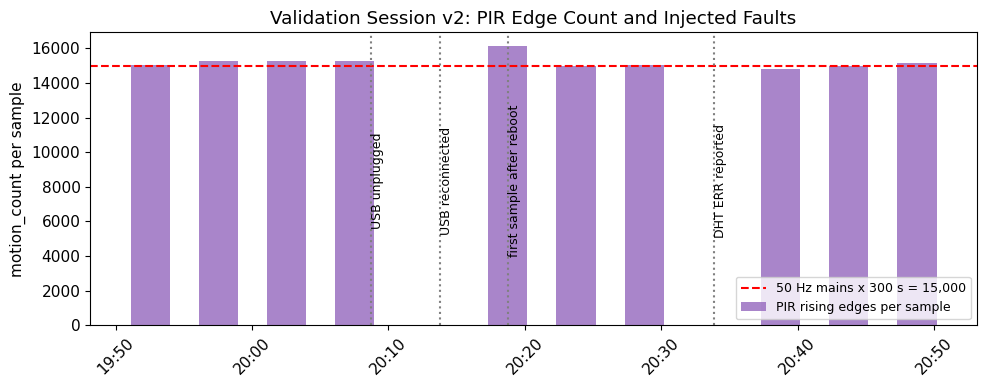

In [22]:
if os.path.exists('raw_data_v2.csv'):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(v2['timestamp'], v2['motion_count'], width=0.002, color='tab:purple', alpha=0.8, label='PIR rising edges per sample')
    ax.axhline(50 * V2_INTERVAL_S, color='red', linestyle='--', label=f'50 Hz mains x {V2_INTERVAL_S} s = {50*V2_INTERVAL_S:,}')
    for t, label in [('2026-09-27 20:08:42', 'USB unplugged'), ('2026-09-27 20:13:47', 'USB reconnected'), ('2026-09-27 20:18:44', 'first sample after reboot'),
                     ('2026-09-27 20:33:50', 'DHT ERR reported')]:
        ax.axvline(pd.Timestamp(t), color='grey', linestyle=':')
        ax.text(pd.Timestamp(t), 50 * V2_INTERVAL_S * 0.55, ' ' + label, rotation=90, fontsize=9, va='center')
    ax.set_ylabel('motion_count per sample')
    ax.set_title('Validation Session v2: PIR Edge Count and Injected Faults')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.legend(fontsize=9, loc='lower right')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig('fig5_v2_pir_noise.png', dpi=150)
    plt.show()

In [23]:
if os.path.exists('errors_v2.log'):
    with open('errors_v2.log') as fh:
        lines = [l.strip() for l in fh if l.strip()]
    categories = {'arduino reported': 'DHT failure (ERR)', 'watchdog': 'Watchdog timeout',
                  'seq reset': 'Arduino reboot', 'gap:': 'Missing samples (seq)',
                  'serial lost': 'USB disconnected', 'cannot open': 'Reconnect attempt',
                  'malformed': 'Malformed line', 'out of range': 'Out-of-range value'}
    counts = {label: sum(key in l for l in lines) for key, label in categories.items()}
    print(pd.Series(counts).to_string())
    print("\nFull log:")
    print("\n".join(lines))
else:
    print("errors_v2.log not found")

DHT failure (ERR)         1
Watchdog timeout          1
Arduino reboot            1
Missing samples (seq)     1
USB disconnected          1
Reconnect attempt        61
Malformed line            0
Out-of-range value        0

Full log:
2026-09-27T20:08:42.753332 serial lost, reconnecting
2026-09-27T20:08:42.755692 cannot open COM3: could not open port 'COM3': FileNotFoundError(2, 'The system cannot find the file specified.', None, 2); retry in 5s
2026-09-27T20:08:47.758031 cannot open COM3: could not open port 'COM3': FileNotFoundError(2, 'The system cannot find the file specified.', None, 2); retry in 5s
2026-09-27T20:08:52.759639 cannot open COM3: could not open port 'COM3': FileNotFoundError(2, 'The system cannot find the file specified.', None, 2); retry in 5s
2026-09-27T20:08:57.761866 cannot open COM3: could not open port 'COM3': FileNotFoundError(2, 'The system cannot find the file specified.', None, 2); retry in 5s
2026-09-27T20:09:02.763432 cannot open COM3: could not open port

## Part 5: Privacy Safeguards 
Before any data is shared, timestamps are rounded to 15-minute blocks, identifiers are replaced with an anonymous room ID, occupancy is reduced to a binary flag per block, and raw rows older
than 30 days are deleted.

In [24]:
shared = anonymise_for_sharing(df, room_id='ROOM_A', freq='15min')
print(f"Raw rows: {len(df)} (5-min, exact timestamps)  ->  shared rows: {len(shared)} (15-min blocks)")
print(f"Columns shared: {list(shared.columns)}")
kept = apply_retention(df, now=df['timestamp'].max() + pd.Timedelta(days=31))
print(f"Retention check: rows kept 31 days after collection = {len(kept)}")
shared.head()

Raw rows: 48 (5-min, exact timestamps)  ->  shared rows: 17 (15-min blocks)
Columns shared: ['room_id', 'timestamp', 'temperature', 'humidity', 'occupied']
Retention check: rows kept 31 days after collection = 0


,room_id,timestamp,temperature,humidity,occupied
0,ROOM_A,2026-09-26 20:00:00,23.0,52.2,0
1,ROOM_A,2026-09-26 20:15:00,22.8,52.6,1
2,ROOM_A,2026-09-26 20:30:00,22.8,53.0,1
3,ROOM_A,2026-09-26 20:45:00,22.1,53.7,0
4,ROOM_A,2026-09-26 21:00:00,22.1,53.6,1


## Part 7: Performance Comparison: One-Step Temperature Forecast
All models are evaluated on the same samples (from the 6th reading onward) so the comparison is fair.

In [25]:
forecast_table = forecast_errors(df['temperature']).round(3)
forecast_table

,model,MAE,RMSE,max_err
0,Persistence (last value),0.274,0.575,2.700
1,EWMA alpha=0.8,0.329,0.644,2.745
2,Linear trend (last 3),0.340,0.630,2.567
3,MA3 (Task 4P),0.509,0.911,3.167
4,MA5,0.723,1.174,3.640


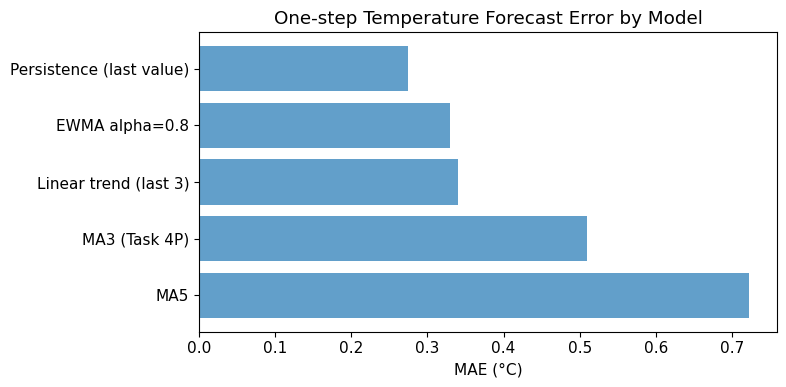

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(forecast_table['model'], forecast_table['MAE'], color='tab:blue', alpha=0.7)
ax.invert_yaxis()
ax.set_xlabel('MAE (\u00b0C)')
ax.set_title('One-step Temperature Forecast Error by Model')
plt.tight_layout()
plt.savefig('fig4_forecast_comparison.png', dpi=150)
plt.show()

## Export

In [27]:
fixed_real = clean_series(df.drop(columns=['comfort_adaptive']))
fixed_real['temp_ma3'] = moving_average(fixed_real['temperature'], 3)
fixed_real['comfort_adaptive'] = fixed_real['temperature'].apply(lambda t: comfort_label(t, band))
fixed_real.to_csv('processed_data_7H.csv', index=False)
comparison.to_csv('table_comfort_comparison.csv', index=False)
forecast_table.to_csv('table_forecast_comparison.csv', index=False)
alert_table.to_csv('table_alerts.csv', index=False)
criteria.to_csv('table_success_criteria.csv', index=False)
shared.to_csv('shared_anonymised_4P.csv', index=False)
print("Saved: processed_data_7H.csv, shared_anonymised_4P.csv and all result tables")

Saved: processed_data_7H.csv, shared_anonymised_4P.csv and all result tables
